# Data Preparation for Actuaries
## A 90-Minute Practical Workshop

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ktnspr/py4lju/blob/main/05_data_preparation.ipynb)

In this session, you will learn to prepare raw data for a model: clean it, construct features, split it into training and test data, fill missing values and scale it.

- **Part 1**: Cleaning Data
- **Part 2**: Constructing and Encoding Features
- **Part 3**: Train/Test Split, Missing Values and Scaling

The explanations use the small table `claims`. All exercises use `vehicle_fraud.csv` from Notebook 03.

In [1]:
# Colab setup: fetch the dataset if not running locally
import sys
if 'google.colab' in sys.modules:
    !wget -qN https://raw.githubusercontent.com/ktnspr/py4lju/main/vehicle_fraud.csv

In [2]:
# Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Seaborn style for all plots
sns.set_theme(style='whitegrid')

# Avoid truncation of DataFrame output in Jupyter
pd.set_option('display.expand_frame_repr', False)

# Display all columns in the DataFrame output
pd.set_option('display.max_columns', None)

# Define a separator for better readability
sep = "=" * 50

## Part 1: Cleaning Data

The table `claims` contains typical problems of raw data. Parts 1 to 3 prepare it step by step for a model.

In [3]:
# Raw data with typical problems
claims = pd.DataFrame({
    'claim_id': [101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 108],
    'age': [45, 38, 23, 61, 999, 26, 52, 68, 55, 29, 27, 47, 68],
    'vehicle_type': ['Compact', 'SUV', 'Compact', 'Luxury', 'SUV', 'SUV', 'Luxury', 'Compact', 'SUV', 'Compact', 'Compact', 'Luxury', 'Compact'],
    'vehicle_value': [14500, 38000, 12000, 120000, 35000, 32000, 72000, 11000, 41000, 16500, 13000, 64000, 11000],
    'schufa_score': [640, 590, np.nan, 720, 610, 480, np.nan, 700, 560, 510, 630, 680, 700],
    'claim_amount': [1200.0, 4100.0, 5400.0, 30000.0, 2800.0, 10500.0, 7200.0, 650.0, 9999999.0, 6100.0, 1500.0, 11500.0, 650.0],
    'fraud': [0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0]
})

print(f"\n{sep}\nRaw Data: claims\n{sep}")
print(claims)


Raw Data: claims
    claim_id  age vehicle_type  vehicle_value  schufa_score  claim_amount  fraud
0        101   45      Compact          14500         640.0        1200.0      0
1        102   38          SUV          38000         590.0        4100.0      0
2        103   23      Compact          12000           NaN        5400.0      1
3        104   61       Luxury         120000         720.0       30000.0      0
4        105  999          SUV          35000         610.0        2800.0      0
5        106   26          SUV          32000         480.0       10500.0      1
6        107   52       Luxury          72000           NaN        7200.0      0
7        108   68      Compact          11000         700.0         650.0      0
8        109   55          SUV          41000         560.0     9999999.0      0
9        110   29      Compact          16500         510.0        6100.0      1
10       111   27      Compact          13000         630.0        1500.0      0
11       1

### 1.1 Duplicates

A double export creates identical rows. `duplicated()` marks every row that repeats an earlier row, `drop_duplicates()` removes them.

In [4]:
# Rows that repeat an earlier row
print(f"\n{sep}\nDuplicates: claims[claims.duplicated()]\n{sep}")
print(claims[claims.duplicated()])


Duplicates: claims[claims.duplicated()]
    claim_id  age vehicle_type  vehicle_value  schufa_score  claim_amount  fraud
12       108   68      Compact          11000         700.0         650.0      0


In [5]:
# Remove the duplicates
claims = claims.drop_duplicates()

print(f"\n{sep}\nNumber of Rows: len(claims)\n{sep}")
print(len(claims))


Number of Rows: len(claims)
12


### 1.2 Impossible Values

`describe()` reveals values outside the possible range, e.g. the age 999 as a code for "unknown". `df.loc[mask, 'column'] = np.nan` replaces them with `NaN`, the marker for a missing value.

In [6]:
# Statistics of the age
print(f"\n{sep}\nStatistical Summary: claims['age'].describe()\n{sep}")
print(claims['age'].describe())


Statistical Summary: claims['age'].describe()
count     12.000000
mean     122.500000
std      276.414215
min       23.000000
25%       28.500000
50%       46.000000
75%       56.500000
max      999.000000
Name: age, dtype: float64


The age 999 is impossible and pulls the mean up to 122.5.

In [7]:
# Replace impossible ages with NaN
claims.loc[claims['age'] > 100, 'age'] = np.nan

print(f"\n{sep}\nAge: claims['age']\n{sep}")
print(claims['age'])


Age: claims['age']
0     45.0
1     38.0
2     23.0
3     61.0
4      NaN
5     26.0
6     52.0
7     68.0
8     55.0
9     29.0
10    27.0
11    47.0
Name: age, dtype: float64


### 1.3 Outliers

A box plot shows values more than 1.5 box lengths above the box as outliers (Notebook 04). With the quartiles $Q_1$ (`25%`) and $Q_3$ (`75%`):

$$\text{upper} = Q_3 + 1.5 \cdot (Q_3 - Q_1)$$

An outlier is either an **error**, e.g. the placeholder 9,999,999 → replace it with `np.nan`, or a **genuine extreme value**, e.g. a large claim → keep it.

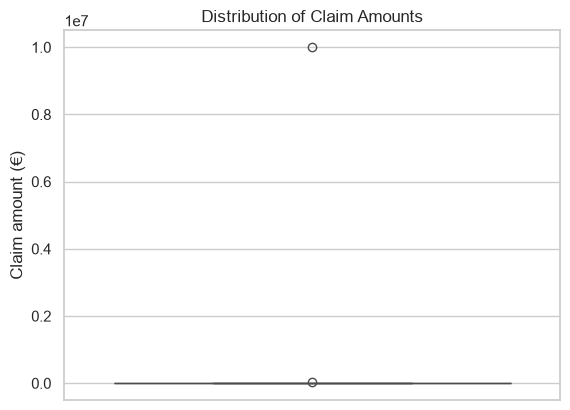

In [8]:
# Box plot of the claim amounts
sns.boxplot(data=claims, y='claim_amount')
plt.title('Distribution of Claim Amounts')
plt.ylabel('Claim amount (€)')
plt.show()

A single extreme value squeezes the box into a line.

In [9]:
# Claims above the upper whisker
q1 = claims['claim_amount'].quantile(0.25)
q3 = claims['claim_amount'].quantile(0.75)
upper = q3 + 1.5 * (q3 - q1)

print(f"\n{sep}\nOutliers: claims[claims['claim_amount'] > upper]\n{sep}")
print(claims[claims['claim_amount'] > upper])


Outliers: claims[claims['claim_amount'] > upper]
   claim_id   age vehicle_type  vehicle_value  schufa_score  claim_amount  fraud
3       104  61.0       Luxury         120000         720.0       30000.0      0
8       109  55.0          SUV          41000         560.0     9999999.0      0


Claim 109 with 9,999,999 is a placeholder: an error. Claim 104 with 30,000 on a luxury car worth 120,000 is genuine and stays.

In [10]:
# Replace the placeholder with NaN
claims.loc[claims['claim_amount'] > 1000000, 'claim_amount'] = np.nan

print(f"\n{sep}\nClaim Amount: claims['claim_amount']\n{sep}")
print(claims['claim_amount'])


Claim Amount: claims['claim_amount']
0      1200.0
1      4100.0
2      5400.0
3     30000.0
4      2800.0
5     10500.0
6      7200.0
7       650.0
8         NaN
9      6100.0
10     1500.0
11    11500.0
Name: claim_amount, dtype: float64


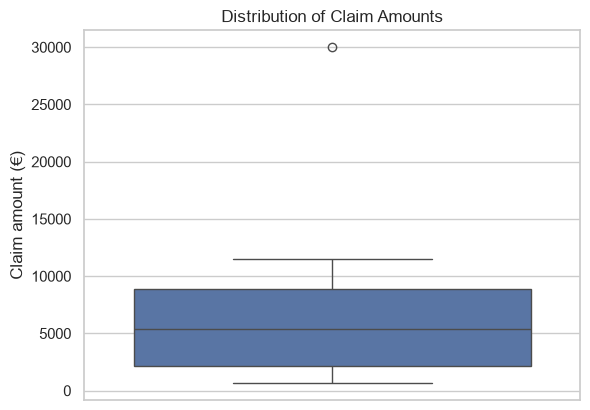

In [11]:
# Box plot without the placeholder
sns.boxplot(data=claims, y='claim_amount')
plt.title('Distribution of Claim Amounts')
plt.ylabel('Claim amount (€)')
plt.show()

The large claim remains an outlier. Section 2.2 reduces its weight with the logarithm.

### 1.4 Missing Values

`isna().sum()` counts the missing values per column. Part 3 fills them. Before that, an indicator column records where `schufa_score` is missing: a missing credit check can itself be a warning sign.

In [12]:
# Missing values per column
print(f"\n{sep}\nMissing Values: claims.isna().sum()\n{sep}")
print(claims.isna().sum())


Missing Values: claims.isna().sum()
claim_id         0
age              1
vehicle_type     0
vehicle_value    0
schufa_score     2
claim_amount     1
fraud            0
dtype: int64


In [13]:
# Indicator column: 1 if schufa_score is missing
claims['schufa_missing'] = claims['schufa_score'].isna().astype(int)

print(f"\n{sep}\nIndicator: claims[['schufa_score', 'schufa_missing']]\n{sep}")
print(claims[['schufa_score', 'schufa_missing']])


Indicator: claims[['schufa_score', 'schufa_missing']]
    schufa_score  schufa_missing
0          640.0               0
1          590.0               0
2            NaN               1
3          720.0               0
4          610.0               0
5          480.0               0
6            NaN               1
7          700.0               0
8          560.0               0
9          510.0               0
10         630.0               0
11         680.0               0


### *Exercise 1: Cleaning `vehicle_fraud.csv`*

1. How many rows are duplicates? Remove them.
2. Find the impossible ages with `describe()` and replace them with `np.nan`.
3. Draw a box plot of `claim_amount`. How many claims lie above the upper whisker?
4. Are the claims above the upper whisker errors? Look at the largest ones and compare the fraud rate above and below the whisker.
5. Count the missing values per column.
6. Add the indicator column `schufa_missing`. Compare the fraud rate of claims with and without `schufa_score`.

In [14]:
# Load the dataset
df = pd.read_csv('vehicle_fraud.csv')

In [15]:
# Task 1: Duplicates
# Hint: df.duplicated().sum()
#       df = df.drop_duplicates()


In [16]:
# Task 2: Impossible ages
# Hint: df['policyholder_age'].describe()
#       df.loc[df['policyholder_age'] < 18, 'policyholder_age'] = np.nan


In [17]:
# Task 3: Box plot and claims above the upper whisker
# Hint: sns.boxplot(data=df, y='claim_amount')
#       q1 = df['claim_amount'].quantile(0.25)
#       q3 = df['claim_amount'].quantile(0.75)
#       upper = q3 + 1.5 * (q3 - q1)
#       (df['claim_amount'] > upper).sum()


In [18]:
# Task 4: Errors or genuine large claims?
# Hint: df.sort_values('claim_amount', ascending=False).head(10)
#       df.groupby(df['claim_amount'] > upper)['fraud'].mean()


In [19]:
# Task 5: Missing values per column
# Hint: df.isna().sum()


In [20]:
# Task 6: Indicator column and fraud rate
# Hint: df['schufa_missing'] = df['schufa_score'].isna().astype(int)
#       df.groupby('schufa_missing')['fraud'].mean()


## Part 2: Constructing and Encoding Features

New columns bring domain knowledge into the data. Each value is computed from its own row only, so these steps can be done before the train/test split.

### 2.1 Ratios

A ratio relates two columns: a claim close to the vehicle value is more suspicious than the same amount on an expensive car.

In [21]:
# Claim amount relative to the vehicle value
claims['claim_value_ratio'] = claims['claim_amount'] / claims['vehicle_value']

print(f"\n{sep}\nNew Column: claim_value_ratio\n{sep}")
print(claims[['claim_amount', 'vehicle_value', 'claim_value_ratio', 'fraud']])


New Column: claim_value_ratio
    claim_amount  vehicle_value  claim_value_ratio  fraud
0         1200.0          14500           0.082759      0
1         4100.0          38000           0.107895      0
2         5400.0          12000           0.450000      1
3        30000.0         120000           0.250000      0
4         2800.0          35000           0.080000      0
5        10500.0          32000           0.328125      1
6         7200.0          72000           0.100000      0
7          650.0          11000           0.059091      0
8            NaN          41000                NaN      0
9         6100.0          16500           0.369697      1
10        1500.0          13000           0.115385      0
11       11500.0          64000           0.179688      0


The three fraudulent claims have the highest ratios.

### 2.2 Logarithm

`np.log()` compresses large values: right-skewed amounts become more symmetric (Notebook 04). The large claim stays in the data but loses its extreme weight.

In [22]:
# Logarithm of the claim amount
claims['log_claim_amount'] = np.log(claims['claim_amount'])

print(f"\n{sep}\nNew Column: log_claim_amount\n{sep}")
print(claims[['claim_amount', 'log_claim_amount']])


New Column: log_claim_amount
    claim_amount  log_claim_amount
0         1200.0          7.090077
1         4100.0          8.318742
2         5400.0          8.594154
3        30000.0         10.308953
4         2800.0          7.937375
5        10500.0          9.259131
6         7200.0          8.881836
7          650.0          6.476972
8            NaN               NaN
9         6100.0          8.716044
10        1500.0          7.313220
11       11500.0          9.350102


The largest claim is 46 times the smallest. After the logarithm, it is only 1.6 times as large.

### 2.3 Flags

`.astype(int)` turns a condition into a 0/1 column.

In [23]:
# Flag for young drivers
claims['young_driver'] = (claims['age'] < 30).astype(int)

print(f"\n{sep}\nNew Column: young_driver\n{sep}")
print(claims[['age', 'young_driver']])


New Column: young_driver
     age  young_driver
0   45.0             0
1   38.0             0
2   23.0             1
3   61.0             0
4    NaN             0
5   26.0             1
6   52.0             0
7   68.0             0
8   55.0             0
9   29.0             1
10  27.0             1
11  47.0             0


### 2.4 One-Hot Encoding

Models need numbers. `pd.get_dummies()` turns a text column into one 0/1 column per category. `drop_first=True` drops the first category because it follows from the others: a claim that is neither Luxury nor SUV is Compact. `dtype=int` gives 0/1 instead of True/False.

In [24]:
# One 0/1 column per vehicle type
claims_encoded = pd.get_dummies(claims, columns=['vehicle_type'], drop_first=True, dtype=int)

print(f"\n{sep}\nEncoded Data: pd.get_dummies(claims, columns=['vehicle_type'], drop_first=True, dtype=int)\n{sep}")
print(claims_encoded)


Encoded Data: pd.get_dummies(claims, columns=['vehicle_type'], drop_first=True, dtype=int)
    claim_id   age  vehicle_value  schufa_score  claim_amount  fraud  schufa_missing  claim_value_ratio  log_claim_amount  young_driver  vehicle_type_Luxury  vehicle_type_SUV
0        101  45.0          14500         640.0        1200.0      0               0           0.082759          7.090077             0                    0                 0
1        102  38.0          38000         590.0        4100.0      0               0           0.107895          8.318742             0                    0                 1
2        103  23.0          12000           NaN        5400.0      1               1           0.450000          8.594154             1                    0                 0
3        104  61.0         120000         720.0       30000.0      0               0           0.250000         10.308953             0                    1                 0
4        105   NaN          35000

### *Exercise 2: Constructing and Encoding Features*

Continue with `df` from Exercise 1.

1. Add `claim_value_ratio`. Compare its mean for fraudulent and legitimate claims.
2. Add `log_claim_amount`. Compare mean and median of `claim_amount` and of `log_claim_amount`.
3. Add the flag `long_delay` = `1` if `reporting_delay_days` is above 30. Compare the fraud rate for both values of the flag.
4. One-hot encode `occupation`, `region`, `vehicle_type` and `coverage_type`. Store the result in `df_encoded`. How many columns does it have?

In [25]:
# Task 1: Claim-to-value ratio
# Hint: df['claim_value_ratio'] = df['claim_amount'] / df['vehicle_value']
#       df.groupby('fraud')['claim_value_ratio'].mean()


In [26]:
# Task 2: Logarithm of the claim amount
# Hint: df['log_claim_amount'] = np.log(df['claim_amount'])
#       df[['claim_amount', 'log_claim_amount']].describe()


In [27]:
# Task 3: Flag for long reporting delays
# Hint: df['long_delay'] = (df['reporting_delay_days'] > 30).astype(int)
#       df.groupby('long_delay')['fraud'].mean()


In [28]:
# Task 4: One-hot encoding
# Hint: df_encoded = pd.get_dummies(df, columns=[...], drop_first=True, dtype=int)
#       df_encoded.shape


## Part 3: Train/Test Split, Missing Values and Scaling

Parts 1 and 2 computed each value from its own row. Filling missing values and scaling **learn values from the data**: medians, means and standard deviations. They learn them from the training data only and apply them to both sets. Otherwise, information from the test data leaks into the preparation and the test result looks better than it is (**data leakage**).

### 3.1 Features and Target

`X` holds the features, `y` the target `fraud`. The identifier `claim_id` is not a feature.

In [29]:
# Features and target
X = claims_encoded.drop(columns=['claim_id', 'fraud'])
y = claims_encoded['fraud']

print(f"\n{sep}\nFeatures: X.columns.tolist()\n{sep}")
print(X.columns.tolist())


Features: X.columns.tolist()
['age', 'vehicle_value', 'schufa_score', 'claim_amount', 'schufa_missing', 'claim_value_ratio', 'log_claim_amount', 'young_driver', 'vehicle_type_Luxury', 'vehicle_type_SUV']


### 3.2 Train/Test Split

`train_test_split()` sets 20% of the rows aside as test data. `stratify=y` keeps the fraud rate the same in both sets, `random_state=42` makes the split reproducible.

In [30]:
# 80% training data, 20% test data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"\n{sep}\nTest Data: X_test\n{sep}")
print(X_test)


Test Data: X_test
    age  vehicle_value  schufa_score  claim_amount  schufa_missing  claim_value_ratio  log_claim_amount  young_driver  vehicle_type_Luxury  vehicle_type_SUV
4   NaN          35000         610.0        2800.0               0           0.080000          7.937375             0                    0                 1
9  29.0          16500         510.0        6100.0               0           0.369697          8.716044             1                    0                 0
8  55.0          41000         560.0           NaN               0                NaN               NaN             0                    0                 1


Two of the three test rows contain missing values.

### 3.3 Filling Missing Values

`X_train.median()` computes the median of every column from the training data. `fillna(medians)` fills both sets with these medians. Large claims hardly affect the median.

In [31]:
# Medians from the training data
medians = X_train.median()

print(f"\n{sep}\nMedians: X_train.median()\n{sep}")
print(medians)


Medians: X_train.median()
age                       45.000000
vehicle_value          32000.000000
schufa_score             640.000000
claim_amount            5400.000000
schufa_missing             0.000000
claim_value_ratio          0.115385
log_claim_amount           8.594154
young_driver               0.000000
vehicle_type_Luxury        0.000000
vehicle_type_SUV           0.000000
dtype: float64


In [32]:
# Fill both sets with the training medians
X_train = X_train.fillna(medians)
X_test = X_test.fillna(medians)

print(f"\n{sep}\nTest Data: X_test\n{sep}")
print(X_test)


Test Data: X_test
    age  vehicle_value  schufa_score  claim_amount  schufa_missing  claim_value_ratio  log_claim_amount  young_driver  vehicle_type_Luxury  vehicle_type_SUV
4  45.0          35000         610.0        2800.0               0           0.080000          7.937375             0                    0                 1
9  29.0          16500         510.0        6100.0               0           0.369697          8.716044             1                    0                 0
8  55.0          41000         560.0        5400.0               0           0.115385          8.594154             0                    0                 1


The test data now hold the training medians where values were missing. `schufa_missing` from Section 1.4 still marks the filled credit scores.

### 3.4 Scaling

`StandardScaler` brings every column to mean 0 and standard deviation 1:

$$z = \frac{x - \text{mean}}{\text{standard deviation}}$$

`fit_transform()` learns mean and standard deviation from the training data and scales them. `transform()` scales the test data with the same values. Logistic regression and neural networks need scaled features, tree-based models do not.

In [33]:
# Learn from the training data, apply to both sets
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [34]:
# Scaled training data with column names
print(f"\n{sep}\nScaled Training Data: pd.DataFrame(X_train_scaled, columns=X.columns)\n{sep}")
print(pd.DataFrame(X_train_scaled, columns=X.columns).round(2))


Scaled Training Data: pd.DataFrame(X_train_scaled, columns=X.columns)
    age  vehicle_value  schufa_score  claim_amount  schufa_missing  claim_value_ratio  log_claim_amount  young_driver  vehicle_type_Luxury  vehicle_type_SUV
0 -1.07          -0.82         -0.08         -0.76           -0.53              -0.57             -0.93          1.41                -0.71             -0.53
1  1.20           2.23          1.27          2.55           -0.53               0.52              1.64         -0.71                 1.41             -0.53
2  0.60           0.86          0.07         -0.09            1.87              -0.69              0.42         -0.71                 1.41             -0.53
3 -0.33          -0.11         -0.69         -0.45           -0.53              -0.63             -0.07         -0.71                -0.71              1.87
4 -1.33          -0.85          0.07         -0.30            1.87               2.12              0.17          1.41                -0.71      

All columns now have the same scale: vehicle values in the tens of thousands and ratios below 1 become comparable.

### *Exercise 3: Train/Test Split, Missing Values and Scaling*

Continue with `df_encoded` from Exercise 2.

1. Split `df_encoded` into the features `X` (without `claim_id` and `fraud`) and the target `y`.
2. Split into 80% training and 20% test data with `stratify=y`. Compare the fraud rate in both sets.
3. Fill the missing values in both sets with the medians of the training data. Check that no missing values remain.
4. Scale the features with `StandardScaler`. Show the first rows of the scaled training data with column names.

In [35]:
# Task 1: Features and target
# Hint: X = df_encoded.drop(columns=['claim_id', 'fraud'])
#       y = df_encoded['fraud']


In [36]:
# Task 2: Train/test split
# Hint: X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
#       y_train.mean(), y_test.mean()


In [37]:
# Task 3: Fill missing values with the training medians
# Hint: medians = X_train.median()
#       X_train = X_train.fillna(medians)
#       X_test = X_test.fillna(medians)
#       X_train.isna().sum().sum(), X_test.isna().sum().sum()


In [38]:
# Task 4: Scaling
# Hint: scaler = StandardScaler()
#       X_train_scaled = scaler.fit_transform(X_train)
#       X_test_scaled = scaler.transform(X_test)
#       pd.DataFrame(X_train_scaled, columns=X.columns).round(2).head()


## Summary

- **Cleaning data:** `drop_duplicates()`, impossible values and placeholders → `np.nan`, errors vs. genuine outliers, indicator column for missing values
- **Constructing and encoding features:** ratios, `np.log()`, flags with `.astype(int)`, `pd.get_dummies()`
- **Learned steps:** `train_test_split()` with `stratify=y`, medians and `StandardScaler` from the training data only

Next: training machine learning models in Notebook 06.

- [Pandas: Working with Missing Data](https://pandas.pydata.org/docs/user_guide/missing_data.html)
- [scikit-learn: Preprocessing Data](https://scikit-learn.org/stable/modules/preprocessing.html)